# Food Texture Dataset EDA

This notebook explores the food texture dataset to understand variable distributions, relationships, and data quality before any modeling work.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
import seaborn as sns

root_candidates = [Path.cwd(), Path.cwd().parent]
for base in root_candidates:
    data_path = base / 'food_texture' / 'food-texture.csv'
    if data_path.exists():
        break
else:
    data_path = Path(r"D:\APS_lab_019\food_texture\food-texture.csv")

df = pd.read_csv(data_path)
if any(col.lower().startswith('unnamed') for col in df.columns):
    df = df.loc[:, ~df.columns.str.lower().str.startswith('unnamed')]
print(f'Shape: {df.shape}')
print(f'Columns: {list(df.columns)}')

Shape: (50, 5)
Columns: ['Oil', 'Density', 'Crispy', 'Fracture', 'Hardness']


In [2]:
display(df.head())

,Oil,Density,Crispy,Fracture,Hardness
0,16.5,2955,10,23,97
1,17.7,2660,14,9,139
2,16.2,2870,12,17,143
3,16.7,2920,10,31,95
4,16.3,2975,11,26,143


In [3]:
print(df.dtypes)

Oil         float64
Density       int64
Crispy        int64
Fracture      int64
Hardness      int64
dtype: object


In [4]:
print(df.isnull().sum())

Oil         0
Density     0
Crispy      0
Fracture    0
Hardness    0
dtype: int64


In [5]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Oil,50.0,17.202,1.592007,13.7,16.30,16.9,18.10,21.2
Density,50.0,2857.600,124.499980,2570.0,2772.50,2867.5,2945.00,3125.0
Crispy,50.0,11.520,1.775571,7.0,10.00,12.0,13.00,15.0
Fracture,50.0,20.860,5.466073,9.0,17.00,21.0,25.00,33.0
Hardness,50.0,128.180,31.127578,63.0,107.25,126.0,143.75,192.0


In [6]:
# Descriptive statistics
numeric_df = df.select_dtypes(include=[np.number])
desc_stats = numeric_df.describe().transpose()
desc_stats['std'] = numeric_df.std(ddof=1)
display(desc_stats)

print('\nMedian values:')
print(numeric_df.median())

print('\nVariance:')
print(numeric_df.var())

,count,mean,std,min,25%,50%,75%,max
Oil,50.0,17.202,1.592007,13.7,16.30,16.9,18.10,21.2
Density,50.0,2857.600,124.499980,2570.0,2772.50,2867.5,2945.00,3125.0
Crispy,50.0,11.520,1.775571,7.0,10.00,12.0,13.00,15.0
Fracture,50.0,20.860,5.466073,9.0,17.00,21.0,25.00,33.0
Hardness,50.0,128.180,31.127578,63.0,107.25,126.0,143.75,192.0



Median values:
Oil           16.9
Density     2867.5
Crispy        12.0
Fracture      21.0
Hardness     126.0
dtype: float64

Variance:
Oil             2.534486
Density     15500.244898
Crispy          3.152653
Fracture       29.877959
Hardness      968.926122
dtype: float64


In [7]:
# Correlation analysis
sns.set_theme(style='whitegrid')
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
correlation_matrix = df[num_cols].corr(numeric_only=True)

# plt.figure(figsize=(8, 6))
# sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
# plt.title('Feature Correlation Matrix')
# plt.tight_layout()
# plt.show()

print('Pairwise correlation summary:')
print(correlation_matrix.round(2))


Pairwise correlation summary:
           Oil  Density  Crispy  Fracture  Hardness
Oil       1.00    -0.75    0.59     -0.53     -0.10
Density  -0.75     1.00   -0.67      0.57      0.11
Crispy    0.59    -0.67    1.00     -0.84      0.41
Fracture -0.53     0.57   -0.84      1.00     -0.37
Hardness -0.10     0.11    0.41     -0.37      1.00


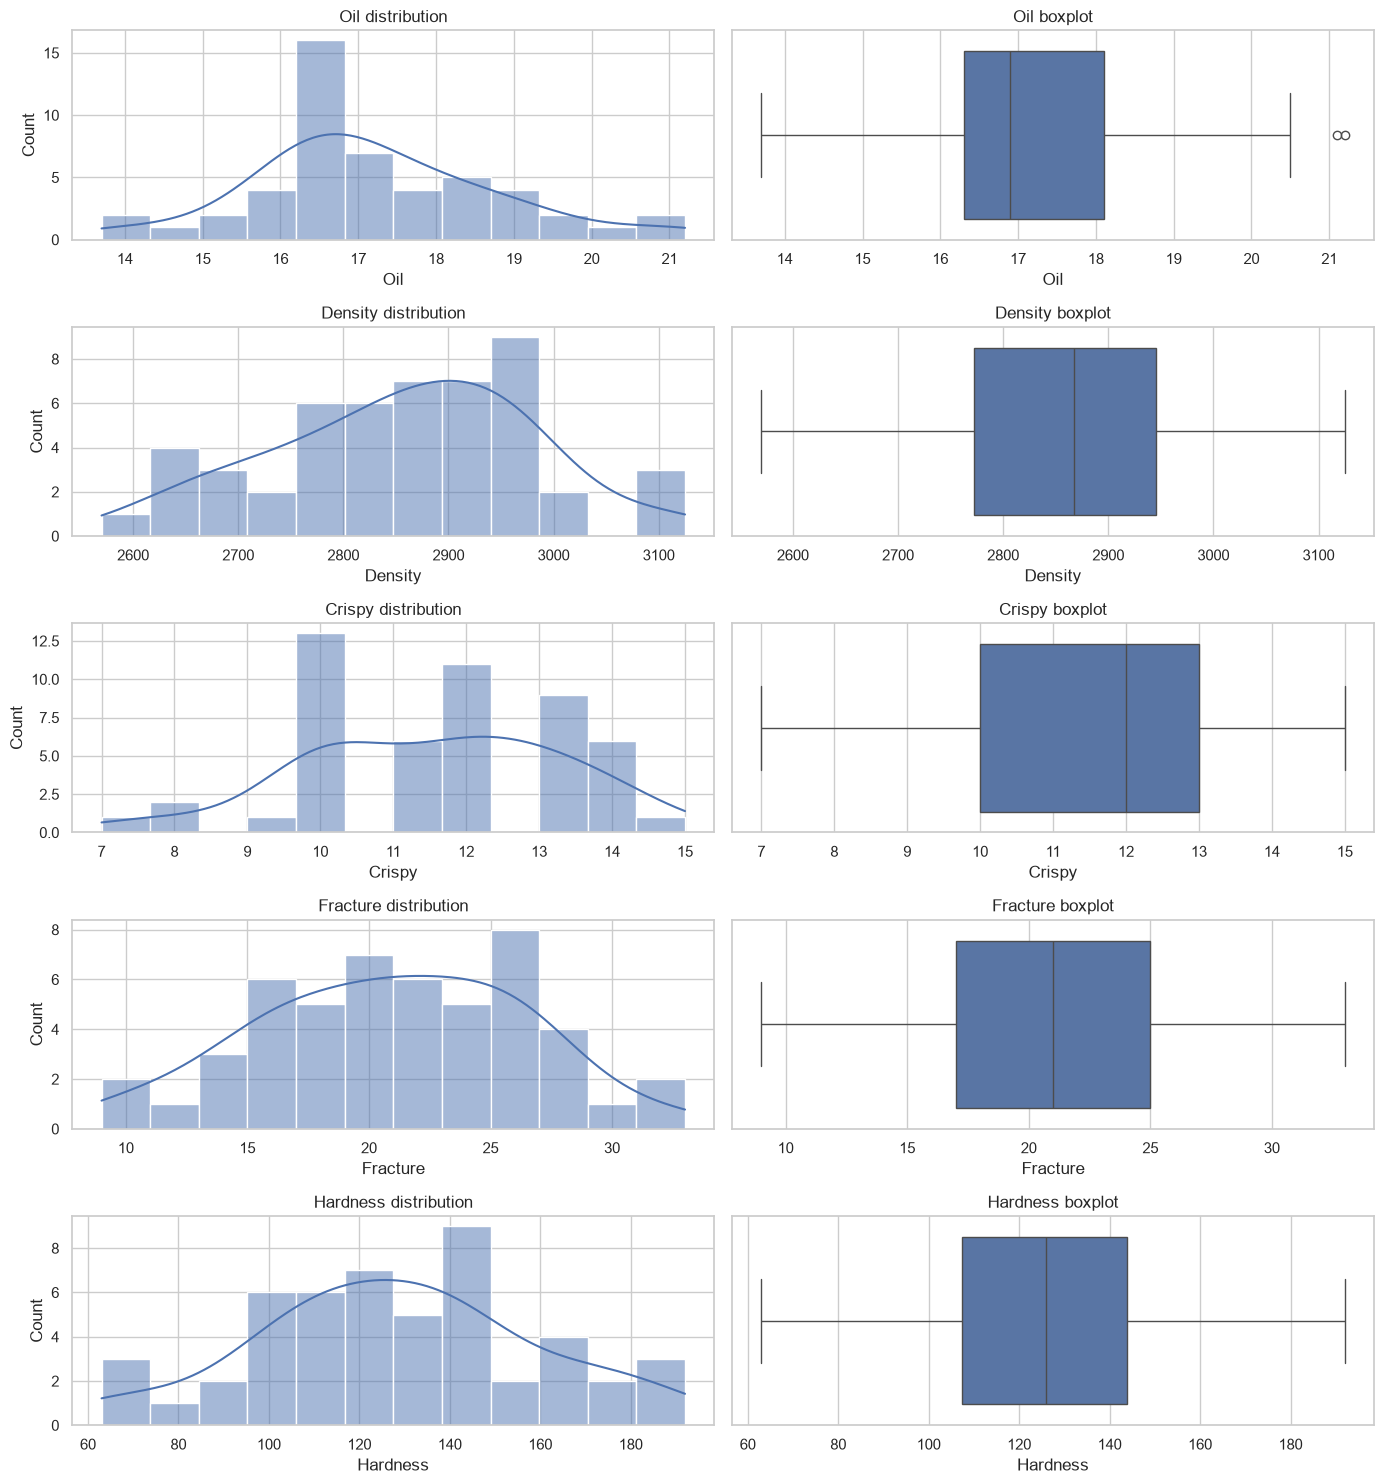

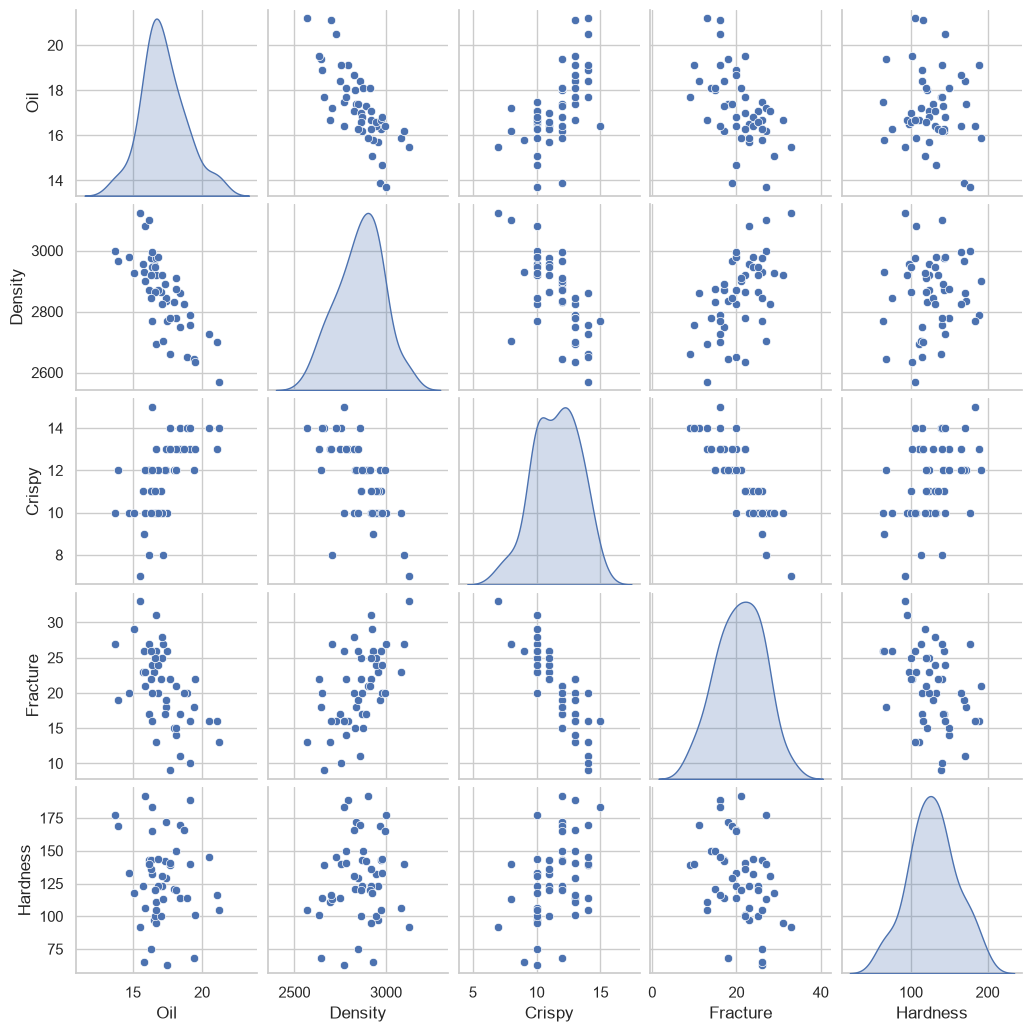

In [17]:
# Distribution and relationship checks
sns.set_theme(style='whitegrid')

# # Histograms for each numeric variable
fig, axes = plt.subplots(len(num_cols), 2, figsize=(14, 3 * len(num_cols)))
for i, col in enumerate(num_cols):
    sns.histplot(df[col], bins=12, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'{col} distribution')
    sns.boxplot(x=df[col], ax=axes[i, 1])
    axes[i, 1].set_title(f'{col} boxplot')

plt.tight_layout()
plt.show()

# # Scatterplot matrix for key relationships
sns.pairplot(df[num_cols], diag_kind='kde', height=2.1)
plt.show()


## Linear Regression

We will predict `Hardness` using the other food texture variables and evaluate the model with a train/test split and standard regression metrics.


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [10]:
# Target and predictors
X = df.drop(columns=['Hardness'])
y = df['Hardness']

In [11]:
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)


In [12]:
# Fit the model
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-4.62, 0.13,12.29,-1.56]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Oil','Density','Crispy','Fracture']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-276.8
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [13]:
# Predictions and metrics
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(rmse)
r2 = r2_score(y_test, predictions)

In [14]:
print('Model intercept:', model.intercept_)
print('\nCoefficients:')
coeff_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': model.coef_
}).sort_values('coefficient', ascending=False)
print(coeff_df.to_string(index=False))
print(f'\nMAE: {mae:.4f}')
print(f'RMSE: {rmse:.4f}')
print(f'R^2: {r2:.4f}')

Model intercept: -276.7505881609768

Coefficients:
 feature  coefficient
  Crispy    12.291354
 Density     0.131103
Fracture    -1.564749
     Oil    -4.619464

MAE: 19.0843
RMSE: 22.7989
R^2: 0.1667


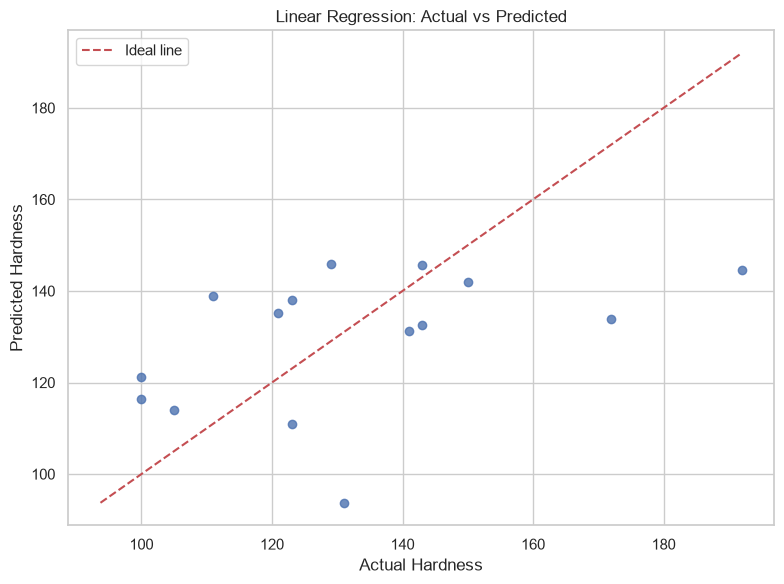

In [15]:
# Scatter plot for predicted vs actual
plt.figure(figsize=(8, 6))
plt.scatter(y_test, predictions, alpha=0.8)
min_val = min(y_test.min(), predictions.min())
max_val = max(y_test.max(), predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal line')
plt.xlabel('Actual Hardness')
plt.ylabel('Predicted Hardness')
plt.title('Linear Regression: Actual vs Predicted')
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# Accuracy check
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R^2: {r2:.4f}")

MAE: 19.0843
RMSE: 22.7989
R^2: 0.1667
